<a href="https://colab.research.google.com/github/keyvanmahmoudi/Machine_Learning_Course/blob/main/solutions/Session06_knn_and_naive_bayes_solutions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

# پاسخ تمرین‌های جلسهٔ ۶: k نزدیک‌ترین همسایه و Naive Bayes

این نوت‌بوک پاسخ پیشنهادی تمرین‌های انتهای [نوت‌بوک جلسه](../sessions/Session06_knn_and_naive_bayes.ipynb) است. قبل از دیدن پاسخ‌ها، خودتان تمرین‌ها را حل کنید؛ معمولاً بیش از یک راه‌حل درست وجود دارد.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### آماده‌سازی

</div>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import root_mean_squared_error
import seaborn as sns

sns.set_theme(style="whitegrid")

DATA_URL = "https://raw.githubusercontent.com/keyvanmahmoudi/Machine_Learning_Course/main/data/"

def plot_decision_boundary(model, X, y, ax, title=""):
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 300),
                         np.linspace(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, 300))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k", s=20)
    ax.set_title(title)

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۱

k-NN را با `weights="distance"` امتحان کنید (همسایه‌های نزدیک‌تر رأی سنگین‌تری دارند). روی دادهٔ moons چه تغییری می‌بینید؟

</div>

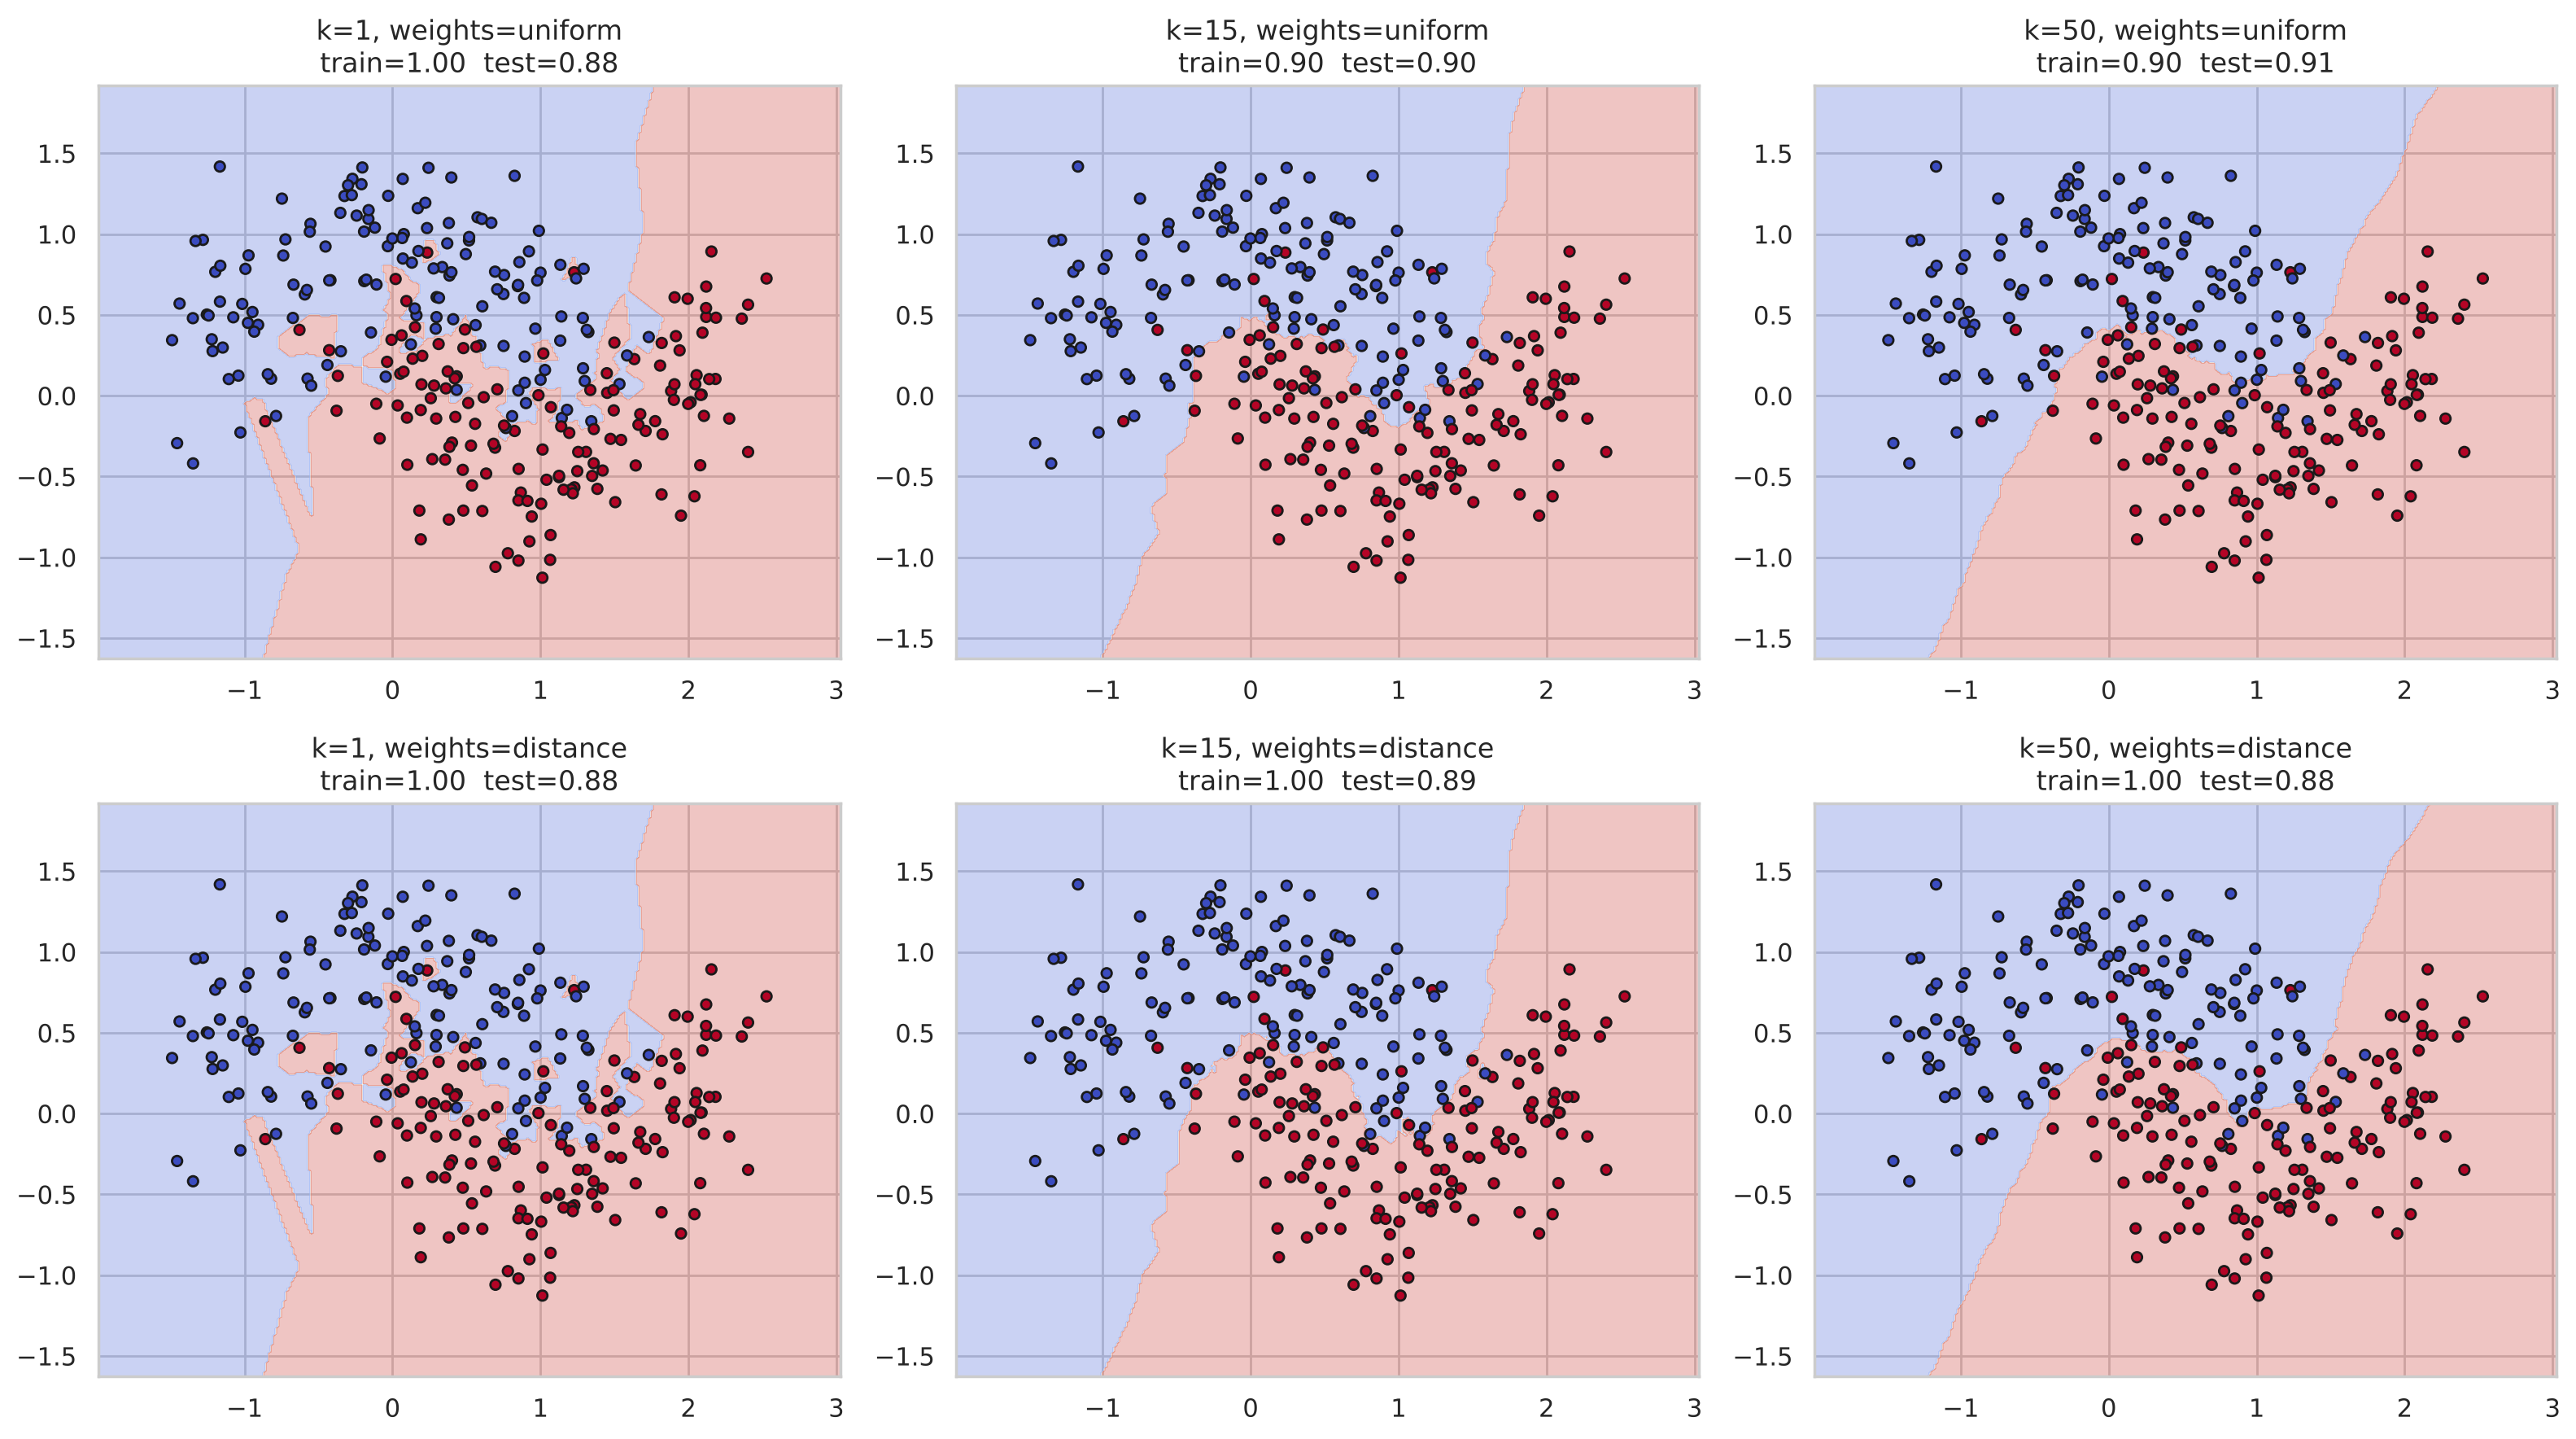

In [2]:
X, y = make_moons(n_samples=400, noise=0.3, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for col, k in enumerate([1, 15, 50]):
    for row, weights in enumerate(["uniform", "distance"]):
        model = KNeighborsClassifier(n_neighbors=k, weights=weights).fit(X_train, y_train)
        plot_decision_boundary(model, X_train, y_train, axes[row, col],
                               f"k={k}, weights={weights}\ntrain={model.score(X_train, y_train):.2f}  "
                               f"test={model.score(X_test, y_test):.2f}")
plt.tight_layout()
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

با `weights="distance"` هر همسایه با وزن عکس فاصله‌اش رأی می‌دهد. چون هر نقطهٔ آموزشی همسایهٔ صفر-فاصلهٔ خودش است، **دقت آموزش همیشه ۱۰۰٪** می‌شود؛ پس دقت آموزش دیگر معیار مفیدی نیست. با $k$ بزرگ، وزن‌دهی بر اساس فاصله مرز را محلی‌تر نگه می‌دارد و از کم‌برازش شدید جلوگیری می‌کند. بهترین ترکیب `n_neighbors` و `weights` را باید با اعتبارسنجی متقابل انتخاب کرد.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۲

`KNeighborsRegressor` را روی دادهٔ مسکن جلسهٔ ۳ اجرا کنید (با مقیاس‌بندی) و RMSE آن را با رگرسیون خطی مقایسه کنید.

</div>

In [3]:
housing = pd.read_csv(DATA_URL + "housing.csv")
Xh = housing.drop(columns="median_house_value")
yh = housing["median_house_value"]
Xh_train, Xh_test, yh_train, yh_test = train_test_split(Xh, yh, test_size=0.2, random_state=42)
numeric = Xh.select_dtypes("number").columns.tolist()
prep = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeric),
    ("cat", OneHotEncoder(handle_unknown="ignore"), ["ocean_proximity"]),
])
for name, model in [("Linear regression", LinearRegression()),
                    ("k-NN regressor (k=10)", KNeighborsRegressor(n_neighbors=10, weights="distance"))]:
    pipe = Pipeline([("prep", prep), ("model", model)]).fit(Xh_train, yh_train)
    print(f"{name:<24} test RMSE = {root_mean_squared_error(yh_test, pipe.predict(Xh_test)):,.0f}")

Linear regression        test RMSE = 70,059
k-NN regressor (k=10)    test RMSE = 60,243


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

k-NN از رگرسیون خطی بهتر است. دلیل: قیمت مسکن به **موقعیت جغرافیایی** وابستگی شدید و غیرخطی دارد و k-NN با میانگین‌گیری از محله‌های مشابه (که معمولاً از نظر مکانی هم نزدیک‌اند)، این الگوی محلی را به‌خوبی می‌گیرد؛ کاری که یک مدل خطی با طول و عرض جغرافیایی نمی‌تواند انجام دهد.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۳

در مدل متنی، `stop_words="english"` را به `TfidfVectorizer` اضافه کنید. دقت تغییر می‌کند؟ چرا حذف کلماتی مثل «not» می‌تواند مضر باشد؟

</div>

In [4]:
reviews = pd.read_csv(DATA_URL + "Restaurant_Reviews.tsv", sep="\t", quoting=3)
Xt_train, Xt_test, yt_train, yt_test = train_test_split(reviews["Review"], reviews["Liked"], test_size=0.2,
                                                        stratify=reviews["Liked"], random_state=42)
for stop_words in [None, "english"]:
    model = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), stop_words=stop_words), MultinomialNB())
    print(f"stop_words={stop_words!s:<8} CV accuracy = {cross_val_score(model, Xt_train, yt_train, cv=5).mean():.3f}")

from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
print("\nNegations in scikit-learn's stop-word list:",
      sorted(w for w in ["not", "no", "never", "nothing", "nor"] if w in ENGLISH_STOP_WORDS))

stop_words=None     CV accuracy = 0.799
stop_words=english  CV accuracy = 0.778

Negations in scikit-learn's stop-word list: ['never', 'no', 'nor', 'not', 'nothing']


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

حذف کلمات پرتکرار (stop words) دقت را پایین می‌آورد. فهرست stop words انگلیسی scikit-learn شامل کلمات **نفی** مثل `not`، `no` و `never` است. در تحلیل احساسات، «good» و «not good» معنای کاملاً متضاد دارند؛ با حذف «not» هر دو به «good» تبدیل می‌شوند. فهرست‌های آمادهٔ stop words برای موتورهای جستجو طراحی شده‌اند، نه برای هر کاربردی؛ همیشه اثرشان را بسنجید.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۴

`alpha` در `MultinomialNB` را با مقادیر ۰٫۰۱، ۰٫۱، ۰٫۵ و ۱ امتحان کنید و بهترین مقدار را با اعتبارسنجی متقابل پیدا کنید.

</div>

In [5]:
from sklearn.model_selection import GridSearchCV

grid = GridSearchCV(make_pipeline(CountVectorizer(), MultinomialNB()),
                    {"multinomialnb__alpha": [0.01, 0.1, 0.5, 1.0]}, cv=5).fit(Xt_train, yt_train)
print(pd.DataFrame(grid.cv_results_)[["param_multinomialnb__alpha", "mean_test_score", "std_test_score"]].round(3))
print("\nBest alpha:", grid.best_params_["multinomialnb__alpha"])
print(f"Test accuracy with the best alpha: {grid.score(Xt_test, yt_test):.3f}")

   param_multinomialnb__alpha  mean_test_score  std_test_score
0                        0.01            0.782           0.043
1                        0.10            0.800           0.038
2                        0.50            0.805           0.033
3                        1.00            0.815           0.025

Best alpha: 1.0
Test accuracy with the best alpha: 0.815


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

`alpha` بسیار کوچک یعنی تقریباً بدون هموارسازی: کلماتی که در یک کلاس دیده نشده‌اند، احتمال نزدیک به صفر می‌گیرند و مدل بیش از حد به کلمات نادر اعتماد می‌کند. `alpha` بزرگ‌تر، احتمال‌ها را نرم‌تر می‌کند. بهترین مقدار را اعتبارسنجی متقابل انتخاب کرده و فقط همان روی دادهٔ آزمون ارزیابی شده است.

</div>